# E-Commerce Customer & Sales Analytics

## Project Overview

This project analyzes transactional e-commerce data to understand sales performance, customer behavior, product performance, geographic patterns, and customer value.

The analysis follows an end-to-end workflow:

**Raw data → Data cleaning → Feature engineering → KPI analysis → Customer analysis → RFM segmentation → Insights**

### Dataset

The project uses the **UCI Online Retail dataset**, containing transactions from a UK-based online retailer between December 2010 and December 2011.

### Main Questions

- How does revenue change over time?
- Which products generate the most revenue and volume?
- Which countries contribute the most revenue?
- How frequently do customers purchase?
- How concentrated is revenue among high-value customers?
- What does the customer base look like using RFM analysis?
- What relationships exist between customer purchase frequency and monetary value?

### Tools

Python, Pandas, NumPy, Matplotlib, and Seaborn.

## 1. Import Libraries

The libraries below are used for data manipulation, numerical analysis, visualization, and statistical exploration.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load the Dataset

The raw Excel file is loaded into a Pandas DataFrame for inspection and cleaning.

In [35]:
df = pd.read_excel("Online Retail.xlsx")

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data Understanding

Before analysis, inspect the structure of the dataset, data types, missing values, duplicates, and the main categorical fields.

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [37]:
missing_values = df.isna().sum().sort_values(ascending=False)

pd.DataFrame({
    "Missing Values": missing_values,
    "Missing %": (missing_values / len(df) * 100).round(2)
})

,Missing Values,Missing %
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [38]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique products:", df["Description"].nunique())
print("Unique countries:", df["Country"].nunique())

Duplicate rows: 5268
Unique products: 4223
Unique countries: 38


## 4. Data Cleaning

The raw transaction data contains duplicate records, cancelled invoices, invalid quantities, invalid prices, and missing customer IDs.

For the sales analysis:

- Duplicate rows are removed.
- Invoices beginning with `C` are treated as cancellations and excluded.
- Transactions with non-positive quantities or prices are excluded.
- Missing `CustomerID` values are retained for overall sales analysis because the transaction can still contribute to revenue.
- A separate customer-level DataFrame is created for analyses that require customer identification.

In [39]:
# Remove duplicate records
df = df.drop_duplicates()

# Identify and remove cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
df = df[~cancelled]

# Remove invalid quantities and prices
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

print(f"Rows after cleaning: {len(df):,}")

Rows after cleaning: 524,878


In [40]:
print("Remaining duplicates:", df.duplicated().sum())
print("Non-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())
print("Missing Customer IDs:", df["CustomerID"].isna().sum())

Remaining duplicates: 0
Non-positive quantities: 0
Non-positive prices: 0
Missing Customer IDs: 132186


## 5. Feature Engineering

Revenue is calculated at the transaction-line level as:

**Revenue = Quantity × Unit Price**

The transaction date is also converted to datetime and a monthly period is created for time-based analysis.

In [41]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M")

# Create customer-level dataset after all required features exist
customer_df = df.dropna(subset=["CustomerID"]).copy()

df[["InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Month"]].head()

,InvoiceDate,Quantity,UnitPrice,Revenue,Month
0,2010-12-01 08:26:00,6,2.55,15.30,2010-12
1,2010-12-01 08:26:00,6,3.39,20.34,2010-12
2,2010-12-01 08:26:00,8,2.75,22.00,2010-12
3,2010-12-01 08:26:00,6,3.39,20.34,2010-12
4,2010-12-01 08:26:00,6,3.39,20.34,2010-12


## 6. Business KPIs

The first set of metrics provides a high-level view of the business during the observation period.

In [42]:
total_revenue = df["Revenue"].sum()
total_orders = df["InvoiceNo"].nunique()
total_customers = customer_df["CustomerID"].nunique()
total_items = df["Quantity"].sum()
aov = total_revenue / total_orders

kpis = {
    "Total Revenue": total_revenue,
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Average Order Value": aov,
    "Total Items Sold": total_items
}

for metric, value in kpis.items():
    if "Revenue" in metric or "Value" in metric:
        print(f"{metric}: £{value:,.2f}")
    else:
        print(f"{metric}: {value:,.0f}")

Total Revenue: £10,642,110.80
Total Orders: 19,960
Total Customers: 4,338
Average Order Value: £533.17
Total Items Sold: 5,572,420


## 7. Time Analysis

Revenue, order volume, and average order value are examined by month to identify changes in sales activity over time.

In [43]:
monthly_revenue = df.groupby("Month")["Revenue"].sum()
monthly_orders = df.groupby("Month")["InvoiceNo"].nunique()
monthly_aov = monthly_revenue / monthly_orders

monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Orders": monthly_orders,
    "AOV": monthly_aov
})

monthly_analysis.sort_values("Revenue", ascending=False).head(10)

,Revenue,Orders,AOV
Month,,,
2011-11,1503866.780,2769,543.108263
2011-10,1151263.730,2040,564.344966
2011-09,1056435.192,1837,575.087203
2010-12,821452.730,1559,526.910026
2011-05,769296.610,1681,457.642243
2011-06,760547.010,1533,496.116771
2011-08,757841.380,1361,556.826877
2011-07,718076.121,1475,486.831268
2011-03,716215.260,1454,492.582710


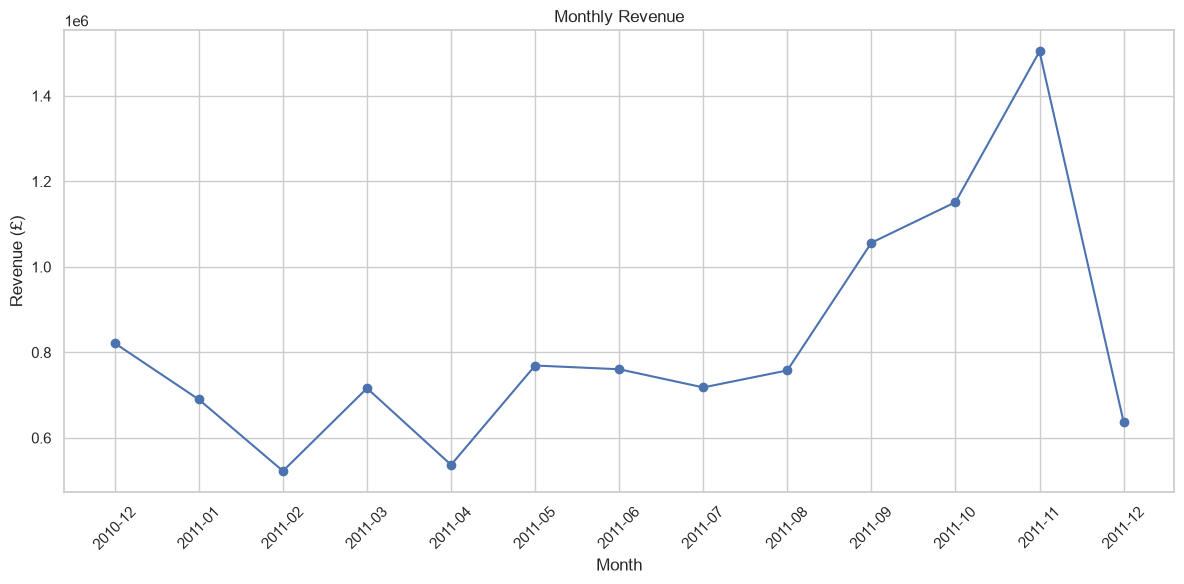

In [44]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_analysis.index.astype(str), monthly_analysis["Revenue"], marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

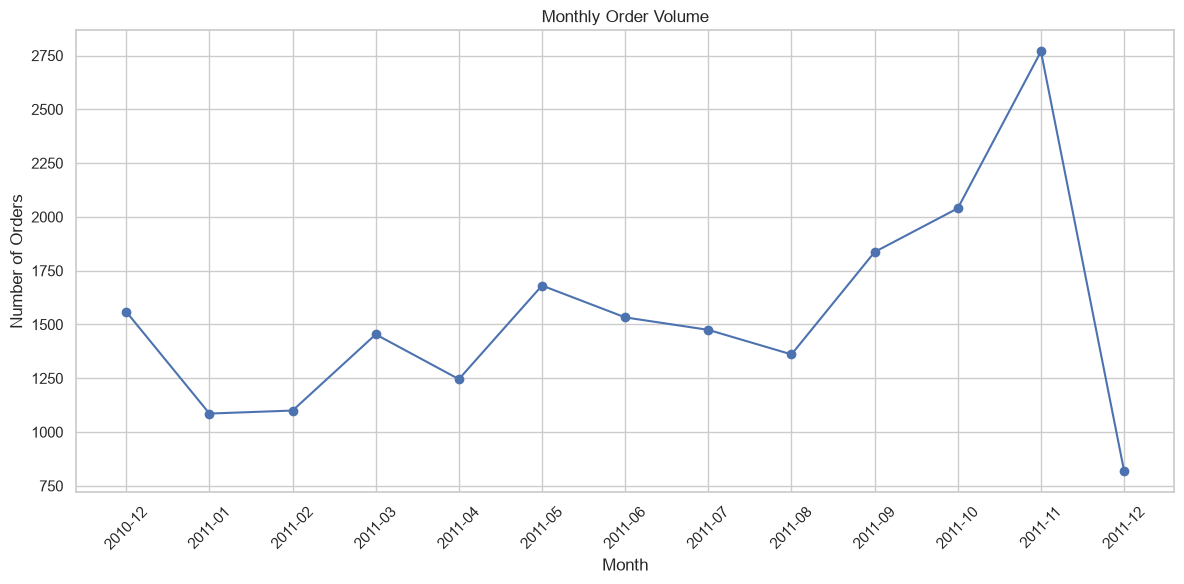

In [45]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_analysis.index.astype(str), monthly_analysis["Orders"], marker="o")
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

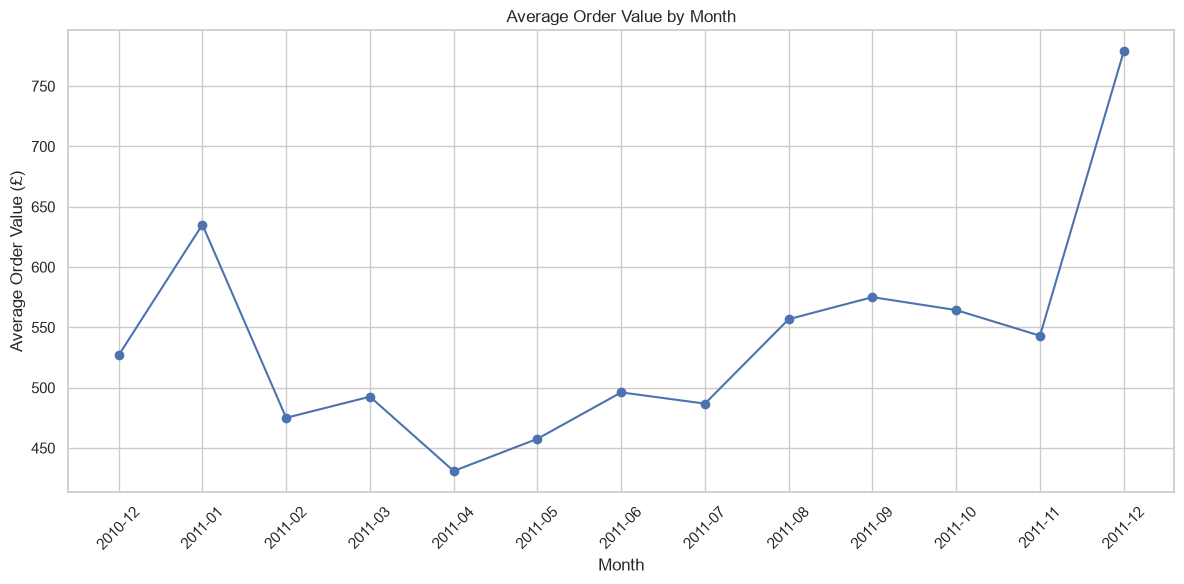

In [46]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_analysis.index.astype(str), monthly_analysis["AOV"], marker="o")
plt.title("Average Order Value by Month")
plt.xlabel("Month")
plt.ylabel("Average Order Value (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Product Analysis

Products are compared using both revenue and quantity sold.

Revenue and quantity measure different aspects of product performance: a high-volume product does not necessarily generate the highest revenue, and vice versa.

In [47]:
product_analysis = df.groupby("Description").agg(
    Revenue=("Revenue", "sum"),
    Quantity=("Quantity", "sum"),
    Average_Unit_Price=("UnitPrice", "mean"),
    Orders=("InvoiceNo", "nunique")
).sort_values("Revenue", ascending=False)

product_analysis.head(10)

,Revenue,Quantity,Average_Unit_Price,Orders
Description,,,,
DOTCOM POSTAGE,206248.77,706,292.137068,706
REGENCY CAKESTAND 3 TIER,174156.54,13851,13.983936,1988
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,2.080000,1
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,3.218334,2256
PARTY BUNTING,99445.23,18283,5.797928,1685
JUMBO BAG RED RETROSPOT,94159.81,48371,2.486197,2089
MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,1.468480,247
POSTAGE,78101.88,3150,31.076581,1126
Manual,77752.82,6985,233.757981,290


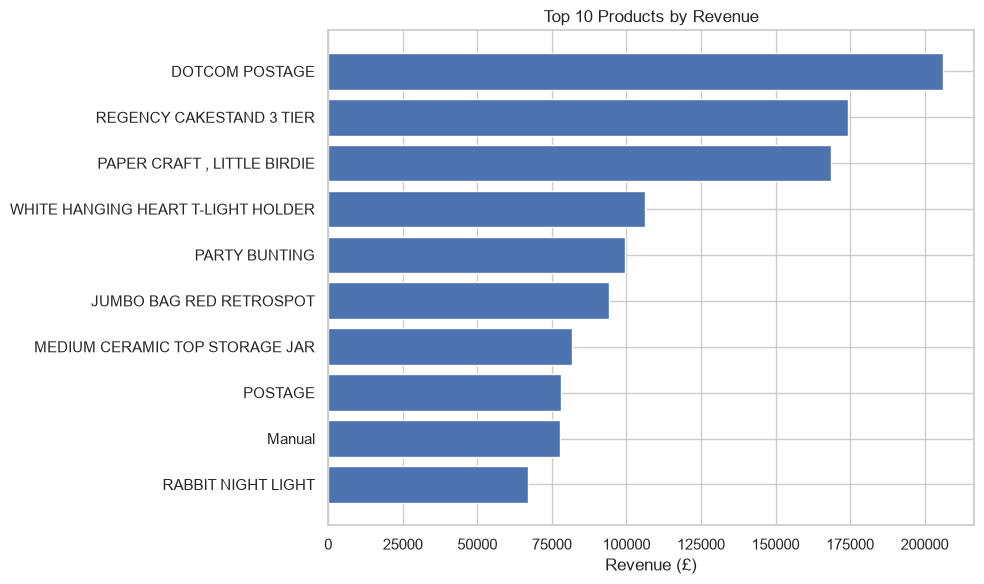

In [48]:
top_products = product_analysis.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products["Revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

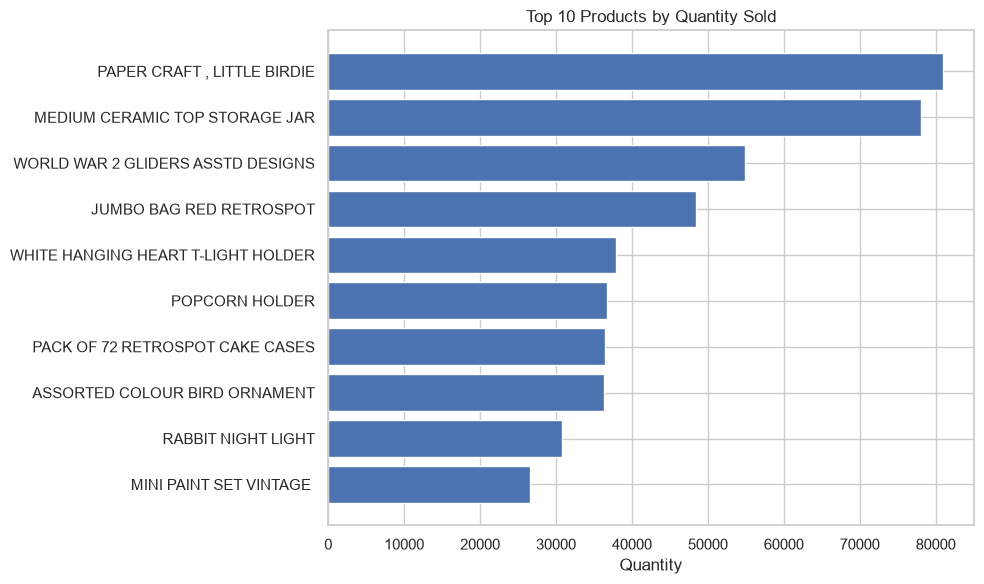

In [49]:
top_quantity = product_analysis.sort_values("Quantity", ascending=False).head(10).sort_values("Quantity")

plt.figure(figsize=(10, 6))
plt.barh(top_quantity.index, top_quantity["Quantity"])
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

### Product Data Quality Check

Some descriptions represent operational items such as postage or manual charges rather than conventional merchandise. These should be considered when interpreting product rankings rather than silently treating every description as a physical product.

The unusually large transaction for `PAPER CRAFT , LITTLE BIRDIE` should also be inspected before drawing conclusions about its product performance.

In [50]:
df[df["Description"] == "PAPER CRAFT , LITTLE BIRDIE"][
    ["InvoiceNo", "Quantity", "UnitPrice", "Revenue", "CustomerID", "Country"]
]

,InvoiceNo,Quantity,UnitPrice,Revenue,CustomerID,Country
540421,581483,80995,2.08,168469.6,16446.0,United Kingdom


## 9. Geographic Analysis

Revenue, order volume, customer count, and average order value are compared across countries.

In [51]:
country_analysis = df.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique")
)

country_analysis["AOV"] = (
    country_analysis["Revenue"] / country_analysis["Orders"]
)

country_analysis = country_analysis.sort_values("Revenue", ascending=False)

country_analysis.head(10)

,Revenue,Orders,Customers,AOV
Country,,,,
United Kingdom,9001744.094,18019,3920,499.569571
Netherlands,285446.340,94,9,3036.663191
EIRE,283140.520,288,3,983.126806
Germany,228678.400,457,94,500.390372
France,209625.370,392,87,534.758597
Australia,138453.810,57,9,2429.014211
Spain,61558.560,90,30,683.984000
Switzerland,57067.600,54,21,1056.807407
Belgium,41196.340,98,25,420.370816


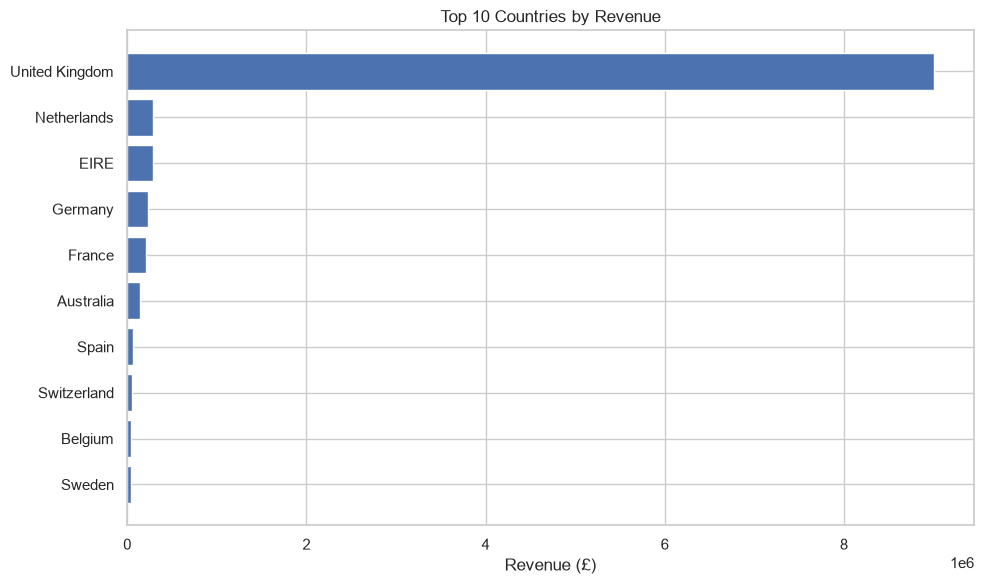

In [52]:
top_countries = country_analysis.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(top_countries.index, top_countries["Revenue"])
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

### AOV Reliability Check

Average order value can be misleading when a country has only a small number of orders. The following comparison therefore focuses on countries with at least 50 orders.

In [53]:
country_reliable = country_analysis[
    country_analysis["Orders"] >= 50
].sort_values("AOV", ascending=False)

country_reliable.head(10)

,Revenue,Orders,Customers,AOV
Country,,,,
Netherlands,285446.340,94,9,3036.663191
Australia,138453.810,57,9,2429.014211
Switzerland,57067.600,54,21,1056.807407
EIRE,283140.520,288,3,983.126806
Spain,61558.560,90,30,683.984000
Portugal,33683.050,58,19,580.742241
France,209625.370,392,87,534.758597
Germany,228678.400,457,94,500.390372
United Kingdom,9001744.094,18019,3920,499.569571


## 10. Customer Analysis

Customer-level analysis uses only transactions with a known `CustomerID`.

The analysis examines purchase frequency, revenue concentration, and the distribution of customer order counts.

In [54]:
customer_analysis = customer_df.groupby("CustomerID").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Items=("Quantity", "sum"),
    Average_Unit_Price=("UnitPrice", "mean")
)

customer_analysis.describe()

,Revenue,Orders,Items,Average_Unit_Price
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,2048.688081,4.272015,1187.644537,4.470820
std,8985.230220,7.697998,5043.619654,34.215024
min,3.750000,1.000000,1.000000,0.122500
25%,306.482500,1.000000,159.000000,2.206415
50%,668.570000,2.000000,378.000000,2.917836
75%,1660.597500,5.000000,989.750000,3.832541
max,280206.020000,209.000000,196915.000000,2033.100000


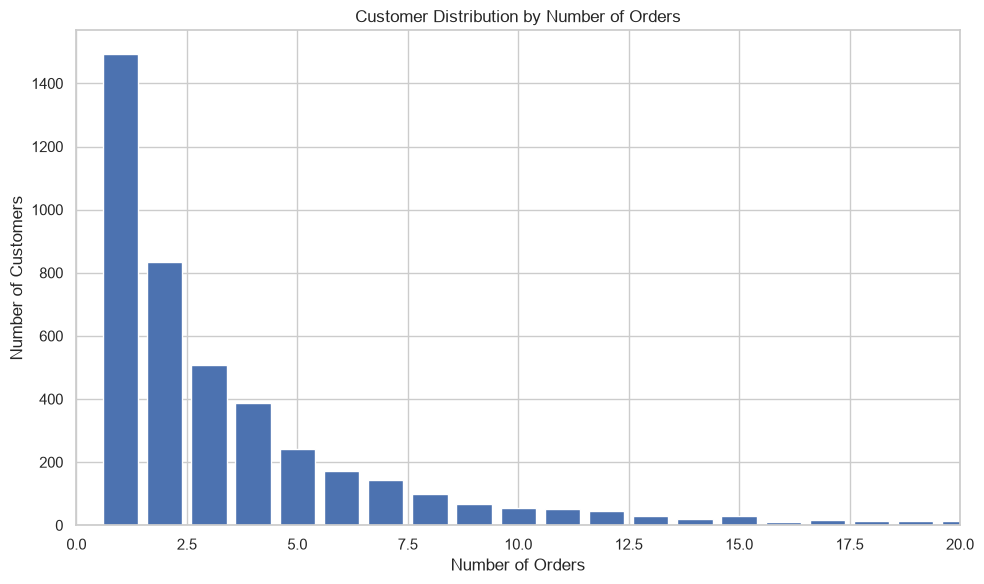

In [55]:
order_frequency = customer_analysis["Orders"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(order_frequency.index, order_frequency.values)
plt.title("Customer Distribution by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.xlim(0, 20)
plt.tight_layout()
plt.show()

In [56]:
customer_segments = pd.cut(
    customer_analysis["Orders"],
    bins=[0, 1, 3, 10, float("inf")],
    labels=["1 order", "2–3 orders", "4–10 orders", "10+ orders"]
)

customer_segments.value_counts().sort_index()

Orders
1 order        1493
2–3 orders     1343
4–10 orders    1165
10+ orders      337
Name: count, dtype: int64

In [57]:
customer_revenue = customer_analysis["Revenue"].sort_values(ascending=False)
total_customer_revenue = customer_revenue.sum()

for n in [1, 5, 10, 50, 100]:
    share = customer_revenue.head(n).sum() / total_customer_revenue * 100
    print(f"Top {n} customers: {share:.2f}% of customer-attributed revenue")

Top 1 customers: 3.15% of customer-attributed revenue
Top 5 customers: 11.77% of customer-attributed revenue
Top 10 customers: 17.30% of customer-attributed revenue
Top 50 customers: 33.30% of customer-attributed revenue
Top 100 customers: 40.61% of customer-attributed revenue


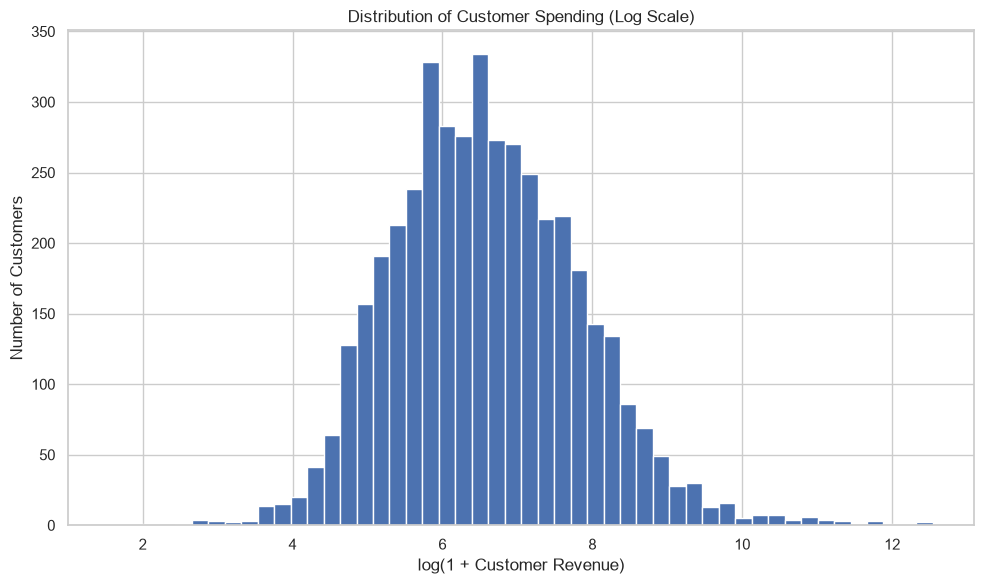

In [58]:
plt.figure(figsize=(10, 6))
plt.hist(np.log1p(customer_analysis["Revenue"]), bins=50)
plt.title("Distribution of Customer Spending (Log Scale)")
plt.xlabel("log(1 + Customer Revenue)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 11. RFM Analysis

RFM analysis evaluates customers using three dimensions:

- **Recency:** How recently the customer purchased
- **Frequency:** How often the customer purchased
- **Monetary:** How much the customer spent

The reference date is one day after the latest transaction in the dataset.

In [59]:
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

recency = (
    analysis_date
    - customer_df.groupby("CustomerID")["InvoiceDate"].max()
).dt.days

frequency = customer_df.groupby("CustomerID")["InvoiceNo"].nunique()
monetary = customer_df.groupby("CustomerID")["Revenue"].sum()

rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


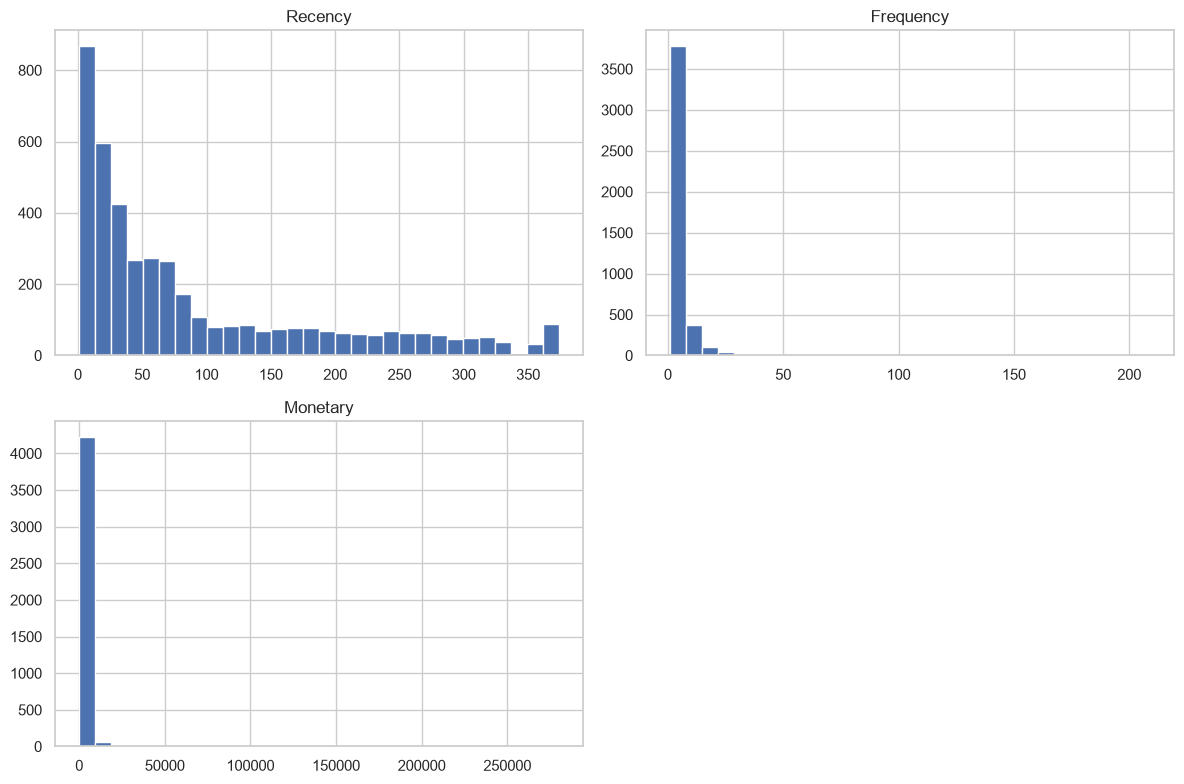

In [60]:
rfm.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

### RFM Scoring

Customers are assigned quintile-based scores from 1 to 5.

For Recency, a lower number of days is better, so the scoring direction is reversed. Frequency and Monetary scores increase as customer activity and spending increase.

In [61]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int)
    + rfm["F_Score"].astype(int)
    + rfm["M_Score"].astype(int)
)

rfm["RFM_Score"].value_counts().sort_index()

RFM_Score
3     183
4     361
5     337
6     426
7     377
8     375
9     336
10    342
11    347
12    321
13    286
14    300
15    347
Name: count, dtype: int64

In [62]:
def segment_customer(score):
    if score >= 13:
        return "High Value"
    elif score >= 10:
        return "Loyal"
    elif score >= 7:
        return "Potential"
    elif score >= 4:
        return "At Risk"
    return "Low Value"

rfm["Segment"] = rfm["RFM_Score"].apply(segment_customer)

rfm["Segment"].value_counts()

Segment
At Risk       1124
Potential     1088
Loyal         1010
High Value     933
Low Value      183
Name: count, dtype: int64

In [63]:
segment_summary = rfm.groupby("Segment")["Monetary"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Total="sum"
).sort_values("Total", ascending=False)

segment_summary

,Count,Mean,Median,Total
Segment,,,,
High Value,933,6689.759668,3000.200,6241545.770
Loyal,1010,1389.110526,1084.865,1403001.631
Potential,1088,807.018118,531.560,878035.712
At Risk,1124,300.904663,257.975,338216.841
Low Value,183,144.311148,141.410,26408.940


In [64]:
rfm.sort_values(
    ["RFM_Score", "Monetary"],
    ascending=[False, False]
).head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
14646.0,2,73,280206.02,5,5,5,15,High Value
18102.0,1,60,259657.30,5,5,5,15,High Value
17450.0,8,46,194390.79,5,5,5,15,High Value
14911.0,1,201,143711.17,5,5,5,15,High Value
14156.0,10,55,117210.08,5,5,5,15,High Value
17511.0,3,31,91062.38,5,5,5,15,High Value
16684.0,4,28,66653.56,5,5,5,15,High Value
14096.0,4,17,65164.79,5,5,5,15,High Value
13694.0,4,50,65039.62,5,5,5,15,High Value


## 12. Correlation Analysis

Correlation is used to examine relationships between Recency, Frequency, and Monetary value.

A correlation does **not** establish causation.

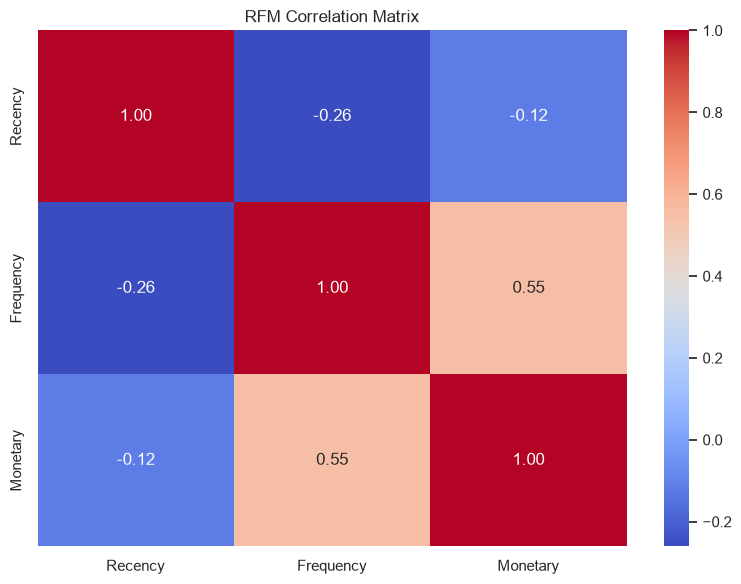

In [65]:
correlation_matrix = rfm[["Recency", "Frequency", "Monetary"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("RFM Correlation Matrix")
plt.tight_layout()
plt.show()

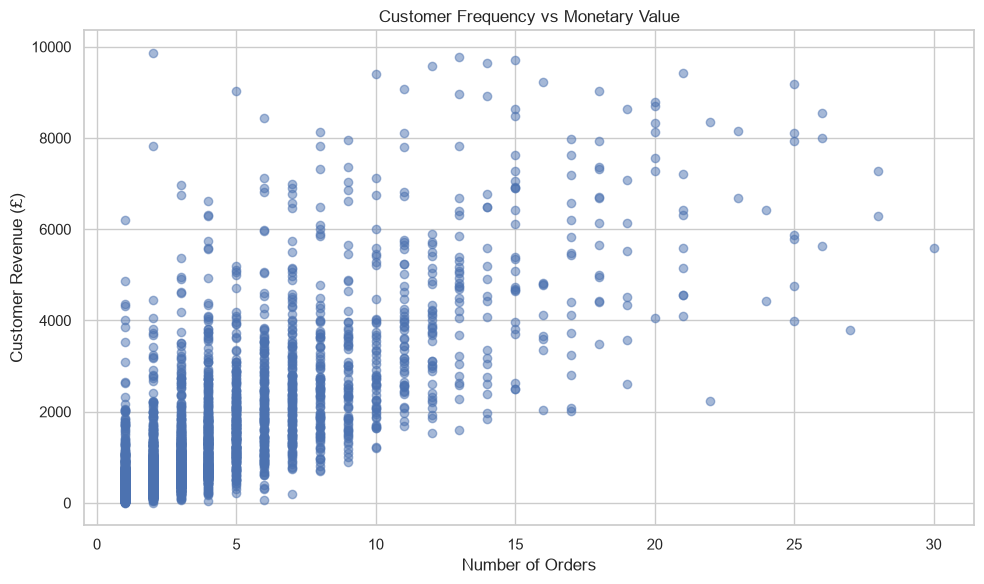

In [66]:
plot_data = rfm[
    (rfm["Frequency"] <= 30)
    & (rfm["Monetary"] <= 10_000)
]

plt.figure(figsize=(10, 6))
plt.scatter(
    plot_data["Frequency"],
    plot_data["Monetary"],
    alpha=0.5
)
plt.title("Customer Frequency vs Monetary Value")
plt.xlabel("Number of Orders")
plt.ylabel("Customer Revenue (£)")
plt.tight_layout()
plt.show()

## 13. Key Findings

Use this section to summarize the most important evidence from the analysis.

Each finding should follow the structure:

**Finding → Evidence → Possible business implication**

Avoid claims of causation unless the analysis provides evidence for a causal relationship.

Suggested findings to complete after reviewing the final outputs:

1. **Overall sales performance:** Summarize total revenue, orders, customers, and AOV.
2. **Time trends:** Identify the strongest revenue months and whether changes are associated with order volume or AOV.
3. **Product performance:** Compare high-revenue products with high-volume products.
4. **Geographic concentration:** Describe the dominance of the UK and the relative contribution of other markets.
5. **Customer behavior:** Quantify one-time versus repeat customers and revenue concentration.
6. **RFM segments:** Explain the size and monetary contribution of each segment.
7. **Customer value relationship:** Discuss the observed relationship between purchase frequency and monetary value without implying causation.

## 14. Limitations

- The dataset covers a specific historical period from one retailer and should not be treated as representative of all e-commerce businesses.
- Missing `CustomerID` values prevent customer-level analysis for some transactions.
- The dataset does not contain explicit profit, cost, or discount information, so revenue should not be interpreted as profit.
- Some transaction descriptions represent operational charges rather than conventional products.
- RFM segments depend on the scoring methodology and thresholds selected in this analysis.
- Correlation analysis identifies associations but does not establish causation.

## 15. Conclusion

This analysis demonstrates an end-to-end workflow for turning raw transactional data into business insights using Python.

The project combines data cleaning, feature engineering, KPI analysis, time-series analysis, product and geographic analysis, customer behavior analysis, and RFM segmentation.
